In [20]:
print("Hello wold")

Hello wold


In [21]:
!ls

classification_model.ipynb
forgery_detection_model.pth
mnist.ipynb
mnist_model_full.pth
mnist_model_weights.pth
model.ipynb
predict.py
recodai-luc-scientific-image-forgery-detection.zip
sample_submission.csv
submission.csv
supplemental_images
supplemental_masks
test_images
train_images
train_masks
venv


In [22]:
import os
from pathlib import Path
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import numpy as np
import torch

class Config:
    """Simple configuration class for data paths and training settings."""
    def __init__(self):
        # Data paths
        self.data_dir = Path(".")
        self.train_images_dir = self.data_dir / "train_images"
        self.train_masks_dir = self.data_dir / "train_masks"
        self.test_images_dir = self.data_dir / "test_images"
        self.supplemental_images_dir = self.data_dir / "supplemental_images"
        self.supplemental_masks_dir = self.data_dir / "supplemental_masks"
        
        # Training settings
        self.batch_size = 32
        self.image_size = (256, 256)
        self.num_workers = 4
        
    def __repr__(self):
        return f"Config(data_dir={self.data_dir}, batch_size={self.batch_size})"

config = Config()
print(config)


Config(data_dir=., batch_size=32)


In [25]:
class ImageDataset(Dataset):
    """Simple dataloader for image and mask pairs."""
    
    def __init__(self, images_dir, masks_dir=None, image_size=(256, 256), transform=None):
        self.images_dir = Path(images_dir)
        self.masks_dir = Path(masks_dir) if masks_dir else None
        self.image_size = image_size
        self.transform = transform
        
        # Memory storage
        self.images_memory = None
        self.masks_memory = None
        self.loaded_to_memory = False
        
        # Get all image files
        if self.images_dir.is_dir():
            if (self.images_dir / "authentic").exists():
                # Handle train_images structure (authentic/forged subdirectories)
                authentic_imgs = list((self.images_dir / "authentic").glob("*.png"))
                forged_imgs = list((self.images_dir / "forged").glob("*.png"))
                self.image_files = authentic_imgs + forged_imgs
            else:
                # Handle flat structure (test_images, supplemental_images)
                self.image_files = list(self.images_dir.glob("*.png"))
        else:
            self.image_files = []
            
        self.image_files.sort()
        
    def __len__(self):
        return len(self.image_files)
    
    def _load_single_item(self, idx):
        """Load a single item from disk (used by both __getitem__ and load_to_memory)."""
        # Load image
        img_path = self.image_files[idx]
        image = Image.open(img_path).convert("RGB")
        image = image.resize(self.image_size)
        image = np.array(image).astype(np.float32) / 255.0
        image = torch.from_numpy(image).permute(2, 0, 1)  # HWC -> CHW
        
        # Load mask if available
        mask = None
        if self.masks_dir:
            mask_name = img_path.stem + ".npy"
            mask_path = self.masks_dir / mask_name
            
            if mask_path.exists():
                mask = np.load(mask_path).astype(np.float32)
                # Squeeze to 2D if needed
                while mask.ndim > 2:
                    if mask.shape[0] == 1:
                        mask = mask[0]
                    elif mask.shape[-1] == 1:
                        mask = mask[..., 0]
                    else:
                        mask = mask[0]
                
                # Normalize mask to 0-255 range for PIL
                if mask.max() <= 1.0:
                    mask_for_pil = (mask * 255).astype(np.uint8)
                else:
                    mask_for_pil = mask.astype(np.uint8)
                
                # Resize mask to match image size
                mask_pil = Image.fromarray(mask_for_pil)
                mask_pil = mask_pil.resize(self.image_size, Image.NEAREST)
                mask = np.array(mask_pil).astype(np.float32) / 255.0
                
                # Add channel dimension
                mask = np.expand_dims(mask, 0)
                mask = torch.from_numpy(mask)
            else:
                # Create empty mask if not found
                mask = torch.zeros((1, *self.image_size))
        
        if self.transform:
            image = self.transform(image)
            if mask is not None:
                mask = self.transform(mask)
        
        return image, mask
    
    def load_to_memory(self, device='cpu', verbose=True):
        """Preload all data into device memory for faster access."""
        if verbose:
            print(f"Loading {len(self.image_files)} items to {device} memory...")
        
        images_list = []
        masks_list = []
        
        for idx in range(len(self.image_files)):
            if verbose and (idx + 1) % 500 == 0:
                print(f"  Loaded {idx + 1}/{len(self.image_files)} items...")
            
            image, mask = self._load_single_item(idx)
            images_list.append(image.to(device))
            if mask is not None:
                masks_list.append(mask.to(device))
            else:
                masks_list.append(None)
        
        self.images_memory = images_list
        self.masks_memory = masks_list
        self.loaded_to_memory = True
        
        if verbose:
            print(f"✓ Loaded {len(self.image_files)} items to {device} memory")
    
    def __getitem__(self, idx):
        # If data is in memory, return from memory
        if self.loaded_to_memory:
            image = self.images_memory[idx]
            mask = self.masks_memory[idx]
            if mask is not None:
                return image, mask
            return image
        
        # Otherwise, load from disk
        image, mask = self._load_single_item(idx)
        if mask is not None:
            return image, mask
        return image

# Create train dataset
train_dataset = ImageDataset(
    images_dir=config.train_images_dir,
    masks_dir=config.train_masks_dir,
    image_size=config.image_size
)

print(f"Train dataset size: {len(train_dataset)}")

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=config.batch_size,
    shuffle=True,
    num_workers=config.num_workers
)

# Test dataset (no masks)
test_dataset = ImageDataset(
    images_dir=config.test_images_dir,
    image_size=config.image_size
)

test_loader = DataLoader(
    test_dataset,
    batch_size=config.batch_size,
    shuffle=False,
    num_workers=config.num_workers
)

print(f"Train batches: {len(train_loader)}")
print(f"Test batches: {len(test_loader)}")


Train dataset size: 5128
Train batches: 161
Test batches: 1


In [26]:
train_dataset.load_to_memory(device='cpu')

Loading 5128 items to cpu memory...
  Loaded 500/5128 items...
  Loaded 1000/5128 items...
  Loaded 1500/5128 items...
  Loaded 2000/5128 items...
  Loaded 2500/5128 items...
  Loaded 3000/5128 items...
  Loaded 3500/5128 items...
  Loaded 4000/5128 items...
  Loaded 4500/5128 items...
  Loaded 5000/5128 items...
✓ Loaded 5128 items to cpu memory


torch.Size([1, 256, 256])


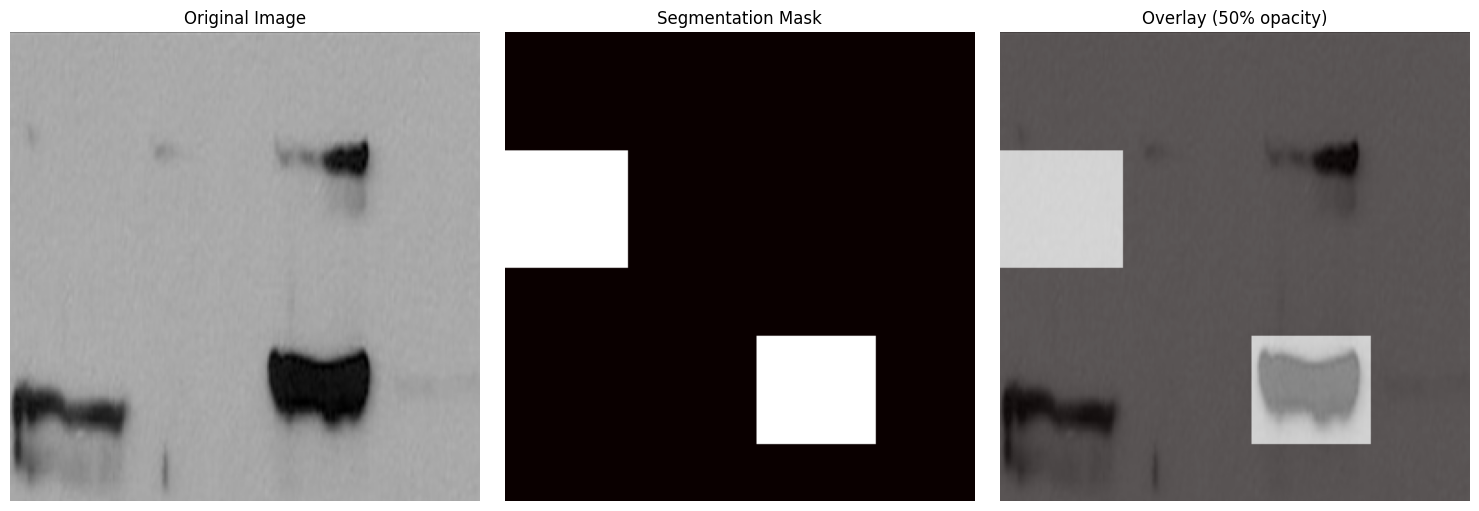

Image shape: (256, 256, 3)
Mask shape: (256, 256)
Mask value range: [0.000, 1.000]
Shapes match: True


In [28]:
import matplotlib.pyplot as plt

# Visualize segmentation with overlay
if len(train_dataset) > 0:
    # Get a sample image and mask
    image, mask = train_dataset[100]
    print(mask.shape)
    
    # Convert from CHW to HWC for matplotlib
    image_np = image.permute(1, 2, 0).numpy()
    
    # Handle mask - if it has channel dimension, take first channel or squeeze
    if mask.dim() == 3:
        mask_np = mask[0].numpy()  # Take first channel if 3D
    else:
        mask_np = mask.numpy()
    
    # Ensure mask is 2D and matches image height/width
    if len(mask_np.shape) > 2:
        mask_np = mask_np.squeeze()
    
    # Normalize mask to [0, 1] if needed
    if mask_np.max() > 1.0:
        mask_np = mask_np / mask_np.max()
    
    # Ensure image and mask have same spatial dimensions
    if image_np.shape[:2] != mask_np.shape[:2]:
        from scipy.ndimage import zoom
        scale_h = image_np.shape[0] / mask_np.shape[0]
        scale_w = image_np.shape[1] / mask_np.shape[1]
        mask_np = zoom(mask_np, (scale_h, scale_w), order=0)  # order=0 for nearest neighbor
    
    # Create figure with subplots
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    # Original image
    axes[0].imshow(image_np)
    axes[0].set_title("Original Image")
    axes[0].axis('off')
    
    # Mask only
    axes[1].imshow(mask_np, cmap='hot')
    axes[1].set_title("Segmentation Mask")
    axes[1].axis('off')
    
    # Overlay with opacity
    axes[2].imshow(image_np)
    axes[2].imshow(mask_np, cmap='hot', alpha=0.5)  # alpha controls opacity
    axes[2].set_title("Overlay (50% opacity)")
    axes[2].axis('off')
    
    plt.tight_layout()
    plt.show()
    
    print(f"Image shape: {image_np.shape}")
    print(f"Mask shape: {mask_np.shape}")
    print(f"Mask value range: [{mask_np.min():.3f}, {mask_np.max():.3f}]")
    print(f"Shapes match: {image_np.shape[:2] == mask_np.shape[:2]}")
else:
    print("No training data available to visualize")


In [ ]:
# Example: Load data to memory (CPU or GPU)
# Uncomment and run this to preload all data to memory

# For CPU:
# train_dataset.load_to_memory(device='cpu')

# For GPU (if available):
# device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# train_dataset.load_to_memory(device=device)

# After loading to memory, __getitem__ will return data from memory instead of disk
# This speeds up training significantly for small-medium datasets
